# Pull Air% by Pitch Type — MLB Analysis
Breaks pull air production into fastball / breaking / offspeed buckets,
both out of all batted balls and out of air balls only, to identify
which pitch type drives the overall Pull Air% signal.


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pd.set_option("display.float_format", "{:.3f}".format)

MIN_BBE = 20   # minimum batted balls per pitch bucket to include

# ── Pitch type bucketing
PITCH_BUCKETS = {
    "fastball": {"FF", "FA", "SI", "FT", "FC"},
    "breaking": {"SL", "ST", "SV", "CU", "KC", "CS"},
    "offspeed": {"CH", "FS", "FO", "EP", "KN"},
}

print("Imports OK")


Imports OK


## 2. Load & Prep

In [2]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))
ip_all   = pd.concat([raw_2024, raw_2025], ignore_index=True)

# Filter to contact events
contact = ip_all[
    ip_all["launch_speed"].notna() &
    ip_all["launch_angle"].notna() &
    ip_all["hc_x"].notna() &
    ip_all["hc_y"].notna() &
    ip_all["stand"].notna() &
    ip_all["pitch_type"].notna()
].copy().reset_index(drop=True)

# ── Spray angle & flags
contact["spray_angle"]      = np.degrees(
    np.arctan((contact["hc_x"] - 125.42) / (198.27 - contact["hc_y"]))
)
contact["spray_angle_norm"] = np.where(
    contact["stand"] == "R",
    contact["spray_angle"],
    -contact["spray_angle"],
)
contact["pull_flag"] = (contact["spray_angle_norm"] > 0).astype(int)
contact["air_ball"]  = (contact["launch_angle"] >= 10).astype(int)
contact["pull_air"]  = (
    (contact["spray_angle_norm"] > 0) & (contact["launch_angle"] >= 10)
).astype(int)
contact["pull_given_air"] = np.where(
    contact["air_ball"] == 1, contact["pull_flag"], np.nan
)

# ── Pitch bucket
def bucket_pitch(pt):
    for bucket, types in PITCH_BUCKETS.items():
        if pt in types:
            return bucket
    return None

contact["pitch_bucket"] = contact["pitch_type"].map(bucket_pitch)
contact = contact[contact["pitch_bucket"].notna()].copy()

print(f"Contact events with pitch bucket: {len(contact):,}")
print(f"\nPitch bucket distribution:")
print(contact["pitch_bucket"].value_counts())

# ── Swing metrics (attack direction normalised)
contact["attack_direction_norm"] = np.where(
    contact["stand"] == "R",
    contact["attack_direction"],
    -contact["attack_direction"],
)


Contact events with pitch bucket: 252,684

Pitch bucket distribution:
pitch_bucket
fastball    144155
breaking     71182
offspeed     37347
Name: count, dtype: int64


## 3. Per-Batter Pull Air% by Pitch Type

In [3]:
def compute_bucket_metrics(df, bucket, min_bbe):
    """
    For one pitch bucket: Pull Air% (out of all BBE) and
    Pull% (out of air balls only).
    """
    sub = df[df["pitch_bucket"] == bucket]
    agg = (
        sub.groupby("batter")
        .agg(
            n_bbe          = ("pull_air",       "count"),
            pull_air_pct   = ("pull_air",       "mean"),   # out of all BBE
            n_air          = ("air_ball",       "sum"),
            pull_given_air = ("pull_given_air", "mean"),   # out of air balls
            air_pct        = ("air_ball",       "mean"),
            pull_pct       = ("pull_flag",      "mean"),
        )
        .query(f"n_bbe >= {min_bbe}")
        .reset_index()
    )
    return agg.rename(columns={
        "pull_air_pct":   f"pull_air_{bucket}",
        "pull_given_air": f"pull_given_air_{bucket}",
        "air_pct":        f"air_pct_{bucket}",
        "pull_pct":       f"pull_pct_{bucket}",
        "n_bbe":          f"n_{bucket}",
        "n_air":          f"n_air_{bucket}",
    })

# Compute for each bucket
bucket_dfs = {}
for bucket in PITCH_BUCKETS:
    bucket_dfs[bucket] = compute_bucket_metrics(contact, bucket, MIN_BBE)
    print(f"{bucket:>10}: {len(bucket_dfs[bucket])} qualified batters")

# Overall Pull Air% for correlation target
overall = (
    contact.groupby("batter")
    .agg(
        n_total        = ("pull_air",       "count"),
        pull_air_all   = ("pull_air",       "mean"),
        pull_given_air = ("pull_given_air", "mean"),
    )
    .query(f"n_total >= {MIN_BBE}")
    .reset_index()
)

# Merge all buckets
merged = overall.copy()
for bucket, df in bucket_dfs.items():
    merged = merged.merge(
        df[["batter", f"pull_air_{bucket}", f"pull_given_air_{bucket}",
            f"air_pct_{bucket}", f"pull_pct_{bucket}",
            f"n_{bucket}", f"n_air_{bucket}"]],
        on="batter", how="left"
    )

print(f"\nMerged batter count: {len(merged)}")
print(f"\nCoverage per bucket (% of batters with ≥{MIN_BBE} BBE):")
for bucket in PITCH_BUCKETS:
    pct = merged[f"pull_air_{bucket}"].notna().mean()
    print(f"  {bucket:>10}: {pct:.1%}")


  fastball: 655 qualified batters
  breaking: 566 qualified batters
  offspeed: 485 qualified batters

Merged batter count: 702

Coverage per bucket (% of batters with ≥20 BBE):
    fastball: 93.3%
    breaking: 80.6%
    offspeed: 69.1%


## 4. Distribution by Pitch Type

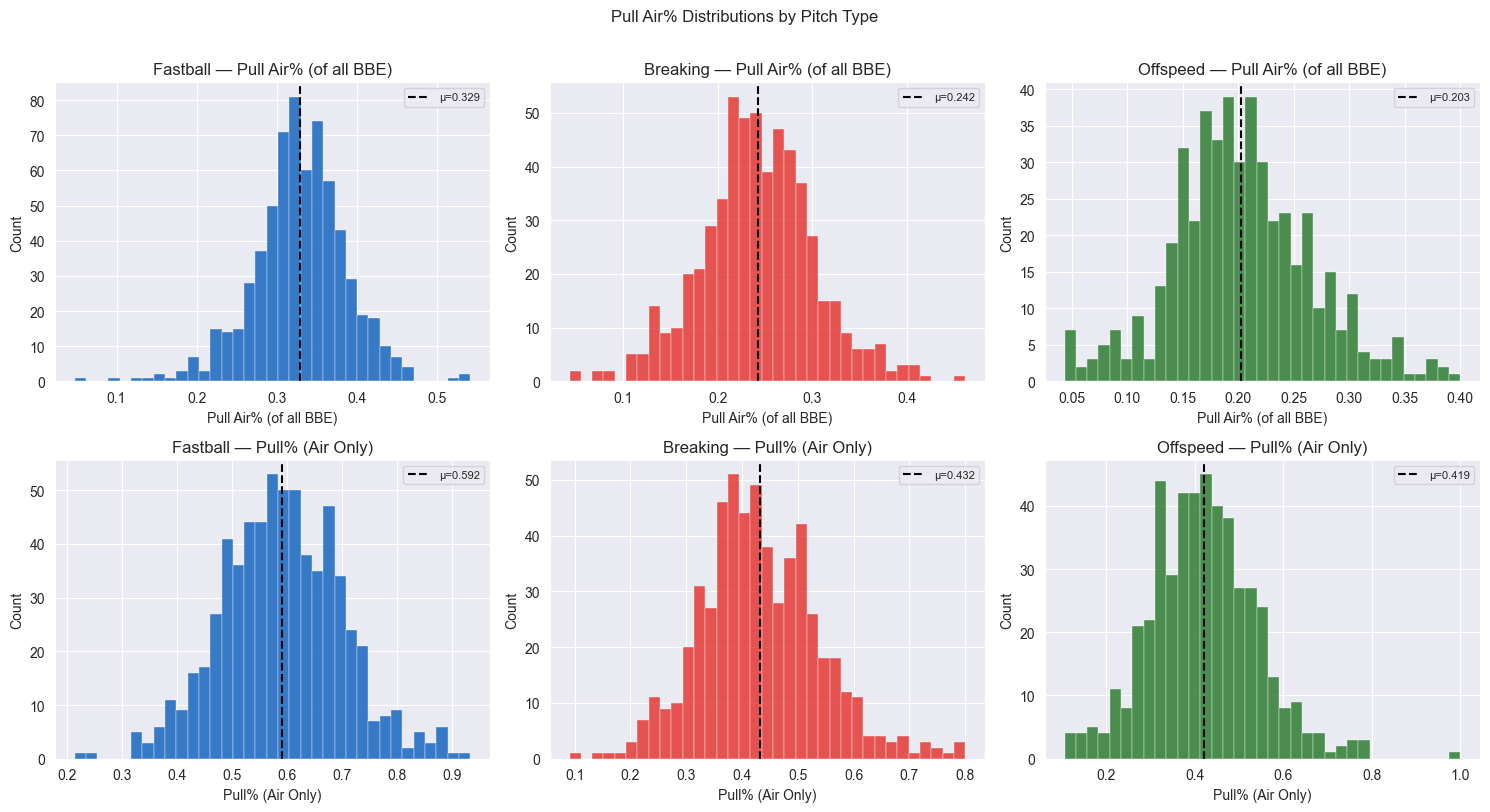


Metric                                  mean      std      min      max
-----------------------------------------------------------------
Pull Air% — fastball                   0.329    0.058    0.048    0.542
Pull% Air Only — fastball              0.592    0.109    0.214    0.933
Pull Air% — breaking                   0.242    0.060    0.043    0.462
Pull% Air Only — breaking              0.432    0.107    0.091    0.800
Pull Air% — offspeed                   0.203    0.063    0.043    0.400
Pull% Air Only — offspeed              0.419    0.122    0.105    1.000


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col_idx, bucket in enumerate(PITCH_BUCKETS):
    for row_idx, (metric, label) in enumerate([
        (f"pull_air_{bucket}",   "Pull Air% (of all BBE)"),
        (f"pull_given_air_{bucket}", "Pull% (Air Only)"),
    ]):
        ax   = axes[row_idx, col_idx]
        data = merged[metric].dropna()
        ax.hist(data, bins=35, color=["#1565C0","#E53935","#2E7D32"][col_idx],
                alpha=0.85, edgecolor="white", linewidth=0.3)
        ax.axvline(data.mean(), color="black", linewidth=1.5, linestyle="--",
                   label=f"μ={data.mean():.3f}")
        ax.set_xlabel(label)
        ax.set_ylabel("Count")
        ax.set_title(f"{bucket.title()} — {label}")
        ax.legend(fontsize=8)

plt.suptitle("Pull Air% Distributions by Pitch Type", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

# Summary stats
print(f"\n{'Metric':<35}  {'mean':>7}  {'std':>7}  {'min':>7}  {'max':>7}")
print("-" * 65)
for bucket in PITCH_BUCKETS:
    for metric, label in [
        (f"pull_air_{bucket}",       f"Pull Air% — {bucket}"),
        (f"pull_given_air_{bucket}", f"Pull% Air Only — {bucket}"),
    ]:
        d = merged[metric].dropna()
        print(f"{label:<35}  {d.mean():>7.3f}  {d.std():>7.3f}  "
              f"{d.min():>7.3f}  {d.max():>7.3f}")


## 5. Correlations with Overall Pull Air%

Metric                                Overall Pull Air%  Overall Pull% AirO
---------------------------------------------------------------------------
Pull Air% — Fastball                             0.8089              0.4242
Pull% Air Only — Fastball                        0.4871              0.8699
Pull Air% — Breaking                             0.5603              0.4314
Pull% Air Only — Breaking                        0.3833              0.6697
Pull Air% — Offspeed                             0.3754              0.2832
Pull% Air Only — Offspeed                        0.2244              0.4836


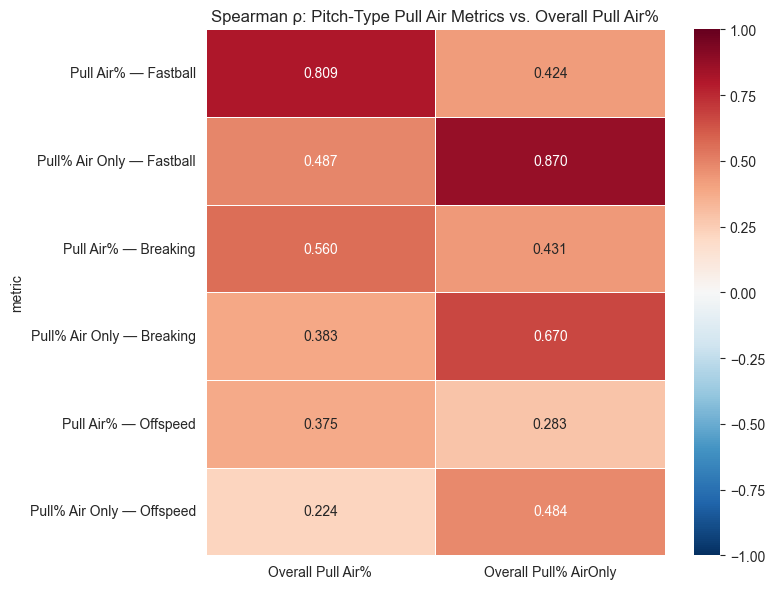

In [5]:
targets = {
    "Overall Pull Air%":    "pull_air_all",
    "Overall Pull% AirOnly":"pull_given_air",
}

bucket_metrics = {}
for bucket in PITCH_BUCKETS:
    bucket_metrics[f"Pull Air% — {bucket.title()}"]      = f"pull_air_{bucket}"
    bucket_metrics[f"Pull% Air Only — {bucket.title()}"] = f"pull_given_air_{bucket}"

print(f"{'Metric':<35}", end="")
for t_label in targets:
    print(f"  {t_label[:18]:>18}", end="")
print()
print("-" * (35 + 20 * len(targets)))

corr_rows = []
for m_label, m_col in bucket_metrics.items():
    row = {"metric": m_label}
    print(f"{m_label:<35}", end="")
    for t_label, t_col in targets.items():
        paired = merged[[m_col, t_col]].dropna()
        if len(paired) < 10:
            print(f"  {'n<10':>18}", end="")
            row[t_label] = np.nan
        else:
            rho, p = spearmanr(paired[m_col], paired[t_col])
            rho    = float(np.asarray(rho).flat[0])
            print(f"  {rho:>18.4f}", end="")
            row[t_label] = rho
    print()
    corr_rows.append(row)

corr_summary = pd.DataFrame(corr_rows).set_index("metric")

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_summary, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax,
            vmin=-1, vmax=1)
ax.set_title("Spearman ρ: Pitch-Type Pull Air Metrics vs. Overall Pull Air%")
plt.tight_layout()
plt.show()


## 6. Stickiness by Pitch Type

Metric                                 ρ (25 BBE)    ρ (50 BBE)    n @ 25
---------------------------------------------------------------------------
Pull Air% — Fastball                       0.3077        0.3106       394
Pull% Air Only — Fastball                  0.6237        0.6404       345
Pull Air% — Breaking                       0.2739        0.3131       313
Pull% Air Only — Breaking                  0.4232        0.4200       234
Pull Air% — Offspeed                       0.0450        0.1248       216
Pull% Air Only — Offspeed                  0.1360           nan         3


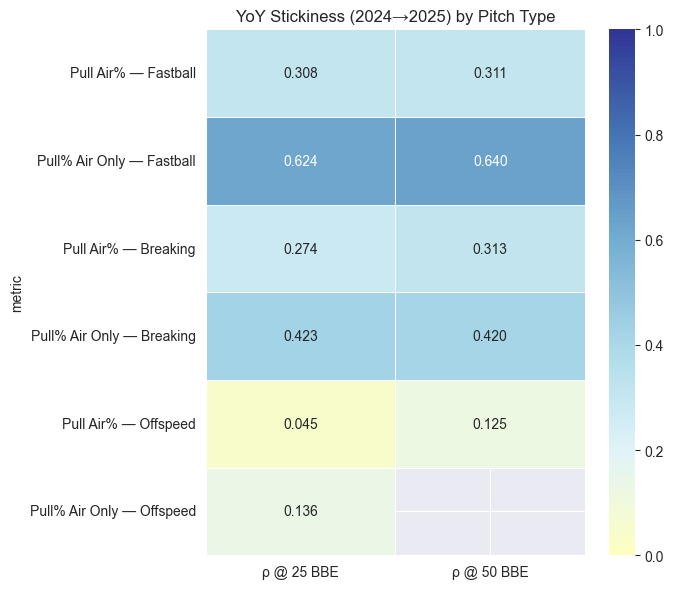

In [9]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))

def prep_contact(df):
    c = df[
        df["launch_speed"].notna() &
        df["launch_angle"].notna() &
        df["hc_x"].notna() &
        df["hc_y"].notna() &
        df["stand"].notna() &
        df["pitch_type"].notna()
    ].copy()
    c["spray_angle_norm"] = np.where(
        c["stand"] == "R",
        np.degrees(np.arctan((c["hc_x"] - 125.42) / (198.27 - c["hc_y"]))),
        -np.degrees(np.arctan((c["hc_x"] - 125.42) / (198.27 - c["hc_y"]))),
    )
    c["pull_flag"]        = (c["spray_angle_norm"] > 0).astype(int)
    c["air_ball"]         = (c["launch_angle"] >= 10).astype(int)
    c["pull_air"]         = ((c["spray_angle_norm"] > 0) & (c["launch_angle"] >= 10)).astype(int)
    c["pull_given_air"]   = np.where(c["air_ball"] == 1, c["pull_flag"], np.nan)
    c["pitch_bucket"]     = c["pitch_type"].map(bucket_pitch)
    return c[c["pitch_bucket"].notna()].copy()

c24 = prep_contact(raw_2024)
c25 = prep_contact(raw_2025)

def season_bucket_means(df, bucket, metric, min_bbe):
    sub = df[df["pitch_bucket"] == bucket]
    if metric == "pull_given_air":
        sub = sub[sub["air_ball"] == 1]
    return (
        sub.groupby("batter")[metric]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")["mean"]
    )

print(f"{'Metric':<35}  {'ρ (25 BBE)':>12}  {'ρ (50 BBE)':>12}  {'n @ 25':>8}")
print("-" * 75)

stick_rows = []
for bucket in PITCH_BUCKETS:
    for metric, label in [
        ("pull_air",       f"Pull Air% — {bucket.title()}"),
        ("pull_given_air", f"Pull% Air Only — {bucket.title()}"),
    ]:
        row = {"metric": label}
        for min_bbe in [25, 50]:
            s24    = season_bucket_means(c24, bucket, metric, min_bbe)
            s25    = season_bucket_means(c25, bucket, metric, min_bbe)
            paired = s24.rename("y2024").to_frame().join(
                s25.rename("y2025"), how="inner"
            )
            if len(paired) < 20:
                row[f"rho_{min_bbe}"] = np.nan
                row["n_25"]           = len(paired)
            else:
                rho, _ = spearmanr(paired["y2024"], paired["y2025"])
                row[f"rho_{min_bbe}"] = float(np.asarray(rho).flat[0])
                if min_bbe == 25:
                    row["n_25"] = len(paired)

        stick_rows.append(row)
        print(f"{label:<35}  {row.get('rho_25', np.nan):>12.4f}  "
              f"{row.get('rho_50', np.nan):>12.4f}  "
              f"{row.get('n_25', 0):>8}")

stick_df = pd.DataFrame(stick_rows).set_index("metric")

# Stickiness heatmap
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(stick_df[["rho_25", "rho_50"]].rename(
                columns={"rho_25": "ρ @ 25 BBE", "rho_50": "ρ @ 50 BBE"}),
            annot=True, fmt=".3f", cmap="RdYlBu", center=0,
            linewidths=0.5, linecolor="white", ax=ax,
            vmin=0, vmax=1)
ax.set_title("YoY Stickiness (2024→2025) by Pitch Type")
plt.tight_layout()
plt.show()


## 7. Regression: Swing Metrics → Pull Air% by Pitch Type

Target                                  CV R²  Top feature             Top coef
--------------------------------------------------------------------------------
Pull Air% — Fastball                   0.0043  Tilt                      0.0075
Pull% Air Only — Fastball              0.1516  Att Ang                  -0.0414
Pull Air% — Breaking                   0.0562  Tilt                      0.0148
Pull% Air Only — Breaking              0.0690  Att Ang                  -0.0192
Pull Air% — Offspeed                   0.0558  Tilt                      0.0181
Pull% Air Only — Offspeed              0.0383  Att Ang                  -0.0258


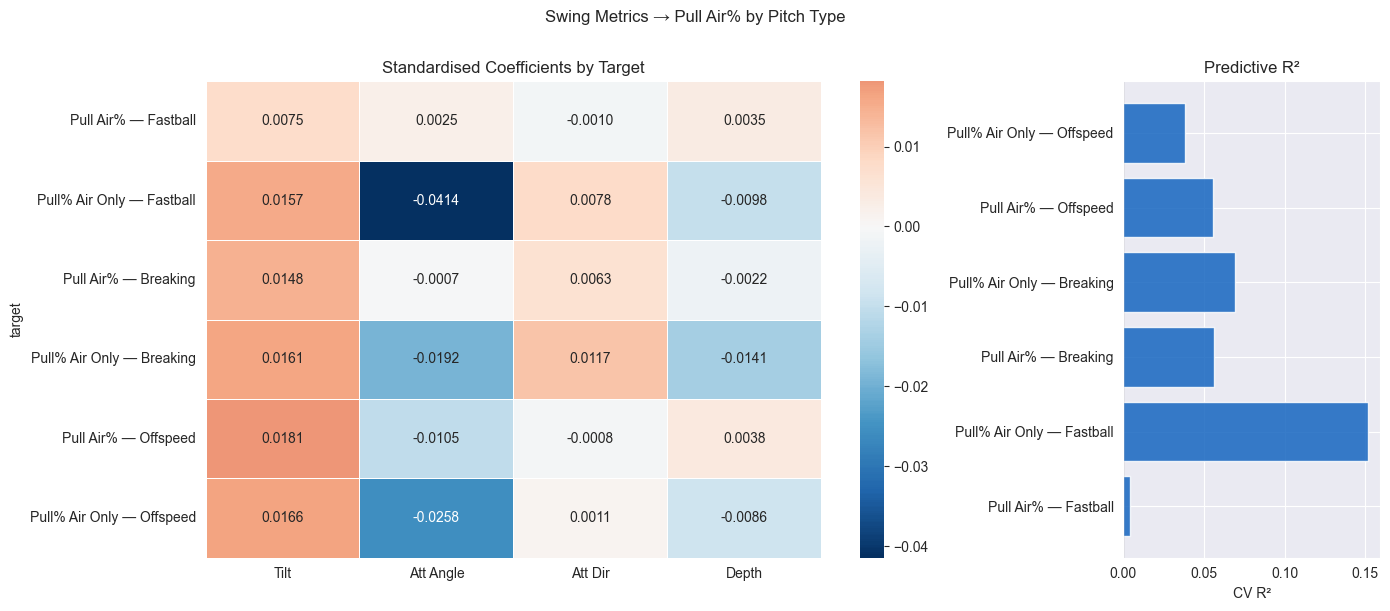

In [7]:
# Swing metrics at batter level
contact_all = pd.concat([c24, c25], ignore_index=True)
contact_all["attack_direction_norm"] = np.where(
    contact_all["stand"] == "R",
    contact_all["attack_direction"],
    -contact_all["attack_direction"],
)

swing_agg = (
    contact_all[contact_all["launch_speed"].notna()]
    .groupby("batter")
    .agg(
        mean_tilt  = ("swing_path_tilt",                         "mean"),
        mean_aa    = ("attack_angle",                             "mean"),
        mean_dir   = ("attack_direction_norm",                    "mean"),
        mean_depth = ("intercept_ball_minus_batter_pos_y_inches", "mean"),
    )
    .reset_index()
)

reg_base = merged.merge(swing_agg, on="batter", how="left")
swing_cols = ["mean_tilt", "mean_aa", "mean_dir", "mean_depth"]

targets_reg = {}
for bucket in PITCH_BUCKETS:
    targets_reg[f"Pull Air% — {bucket.title()}"]      = f"pull_air_{bucket}"
    targets_reg[f"Pull% Air Only — {bucket.title()}"] = f"pull_given_air_{bucket}"

print(f"{'Target':<35}  {'CV R²':>8}  {'Top feature':<20}  {'Top coef':>10}")
print("-" * 80)

reg_results = []
for t_label, t_col in targets_reg.items():
    sub = reg_base[swing_cols + [t_col]].dropna()
    if len(sub) < 20:
        continue
    X = sub[swing_cols].values
    y = sub[t_col].values

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)),
    ])
    pipe.fit(X, y)
    cv_r2  = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()
    coefs  = pipe.named_steps["ridge"].coef_
    top_i  = np.argmax(np.abs(coefs))
    top_f  = ["Tilt", "Att Ang", "Att Dir", "Depth"][top_i]
    top_c  = coefs[top_i]

    reg_results.append({
        "target":      t_label,
        "cv_r2":       cv_r2,
        "Tilt":        coefs[0],
        "Att Angle":   coefs[1],
        "Att Dir":     coefs[2],
        "Depth":       coefs[3],
    })
    print(f"{t_label:<35}  {cv_r2:>8.4f}  {top_f:<20}  {top_c:>10.4f}")

reg_df = pd.DataFrame(reg_results).set_index("target")

# Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                          gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(
    reg_df[["Tilt", "Att Angle", "Att Dir", "Depth"]],
    annot=True, fmt=".4f", cmap="RdBu_r", center=0,
    linewidths=0.5, linecolor="white", ax=axes[0],
)
axes[0].set_title("Standardised Coefficients by Target")

colors = ["#1565C0" if v > 0 else "#E53935" for v in reg_df["cv_r2"]]
axes[1].barh(reg_df.index, reg_df["cv_r2"], color=colors, alpha=0.85)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("CV R²")
axes[1].set_title("Predictive R²")

plt.suptitle("Swing Metrics → Pull Air% by Pitch Type", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()
